In [ ]:
# setups + imports
%load_ext autoreload
%autoreload 2

from config import DATA_PATH

import sys, pickle, time, subprocess
import torch
sys.path.append('..')

from controller import LSTMController
from traj_data_utils import load_resampled
from training_utils import train, evaluate, diagnose, play_sound
from plotting_utils import plot_loss_curves, plot_spectrogram_with_mft

sys.path.append('..')
from QMC_mouseUSV.subglottal_pressure import subglottal_pressure
from QMC_mouseUSV.glottal_area import glottal_area
from QMC_mouseUSV.impingement_length import impingement_length
from QMC_mouseUSV.jet_speed import jet_speed_from_pressure
from QMC_mouseUSV.USVfreq import USVfreq
print("done w/ imports!")

t0 = time.time()
with open("../data_prep/pkl-files/top-pca-model-12.pkl", "rb") as f:
    pca = pickle.load(f)
print(f"pca_model: {time.time() - t0:.2f}s")

t0 = time.time()
with open("../data_prep/pkl-files/train_contours.pkl", "rb") as f:
    train_contours = pickle.load(f)
print(f"train_contours: {time.time() - t0:.2f}s")

t0 = time.time()
with open("../data_prep/pkl-files/test_contours.pkl", "rb") as f:
    test_contours = pickle.load(f)
print(f"test_contours: {time.time() - t0:.2f}s")

t0 = time.time()
with open("../data_prep/pkl-files/top-scaler-12.pkl", "rb") as f:
    scaler = pickle.load(f)
print(f"scaler: {time.time() - t0:.2f}s")

# load pca, scaler, train_contours, test_contours
train_trajs, train_keys = load_resampled(train_contours)
test_trajs, test_keys = load_resampled(test_contours)

print("loaded pca model, n_components available:", pca.n_components_)
print(f"loaded {len(train_contours)} train contours, {len(test_contours)} test contours")
print("setup completed!")

done w/ imports!
pca_model: 1.29s
train_contours: 0.12s
test_contours: 0.01s
scaler: 0.00s
loaded pca model, n_components available: 12
loaded 19787 train contours, 2200 test contours
setup completed!


In [3]:
model = LSTMController(input_dim=12)
model.load_state_dict(torch.load("../data_prep/pkl-files/model-12-comp.pt"))
model.eval()
results = diagnose(model, test_trajs, pca, scaler)

PCA reconstruction vs real (all): 2.415 kHz RMSE
model vs real (all): 2.305 kHz RMSE
model vs PCA reconstruction (all): 1.213 kHz RMSE
PCA reconstruction vs real (jump subset): 4.798 kHz RMSE
model vs real (jump subset): 4.531 kHz RMSE
model vs PCA reconstruction (jump subset): 1.932 kHz RMSE


In [4]:
print(type(results))
print(results.keys() if hasattr(results, "keys") else results)

<class 'dict'>
dict_keys(['model_vs_real_per_example', 'pca_only_per_example', 'jump_mask', 'preds', 'recon'])


In [5]:
import numpy as np
m = np.array(results["model_vs_real_per_example"])
p = np.array(results["pca_only_per_example"])
j = np.array(results["jump_mask"]).astype(bool)
print(j.sum(), "jump calls")
print(round(100 * (m[j] > p[j]).mean()), "percent where the model is worse than compression alone")
print(round(100 * (m[~j] > p[~j]).mean()), "percent for the other calls")

220 jump calls
19 percent where the model is worse than compression alone
55 percent for the other calls


In [6]:
import pandas as pd
df = pd.DataFrame({
    "key": test_keys,
    "model_err": results["model_vs_real_per_example"],
    "pca_err": results["pca_only_per_example"],
    "jump": results["jump_mask"],
})
df["extra"] = df["model_err"] - df["pca_err"]
print(df.sort_values("model_err", ascending=False).head(20))

                key  model_err    pca_err   jump     extra
1418   DBA_3168_248  12.381292  11.929628   True  0.451665
991     DBA_3245_10  12.342564  11.329334   True  1.013230
611   DBA_9857_1206  11.408680  12.662208   True -1.253528
1329   DBA_9858_994  10.838592  10.963926   True -0.125334
1445  DBA_3170_1786  10.443555   9.718222   True  0.725332
492    DBA_3247_759  10.115674   9.971247   True  0.144427
1586  DBA_9859_1160   9.980945   9.097236   True  0.883709
1432    DBA_3168_50   9.550406   9.338405   True  0.212001
391    DBA_9856_589   9.351459   8.340041  False  1.011418
1163   DBA_3168_676   9.341479   8.889223  False  0.452255
199    DBA_3246_564   9.205624   6.855076   True  2.350548
764    DBA_3248_431   8.785717   9.730195   True -0.944479
1550   DBA_3172_638   8.297729   8.120442   True  0.177287
1693   DBA_9858_705   8.260634   8.144052   True  0.116582
981   DBA_3249_1043   8.240067   8.686471   True -0.446403
1702   DBA_3244_697   8.183865   8.415350   True -0.2314

In [7]:
worst = df.sort_values("model_err", ascending=False).head(100)
print(round(100 * worst["jump"].mean()), "percent of the worst 100 are jump calls")
print(round(100 * df["jump"].mean()), "percent of all calls are jump calls")

54 percent of the worst 100 are jump calls
10 percent of all calls are jump calls


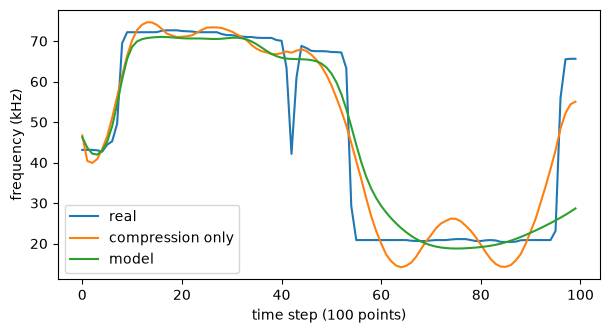

In [10]:
from config import DATA_PATH

import numpy as np, matplotlib.pyplot as plt
i = list(test_keys).index("DBA_3246_564")

def khz(x):
    x = np.asarray(x, float)
    return x / 1000 if np.nanmax(x) > 1000 else x

plt.figure(figsize=(7, 3.5))
plt.plot(khz(test_trajs[i]), label="real")
plt.plot(khz(results["recon"][i]), label="compression only")
plt.plot(khz(results["preds"][i]), label="model")
plt.xlabel("time step (100 points)")
plt.ylabel("frequency (kHz)")
plt.legend()
plt.show()

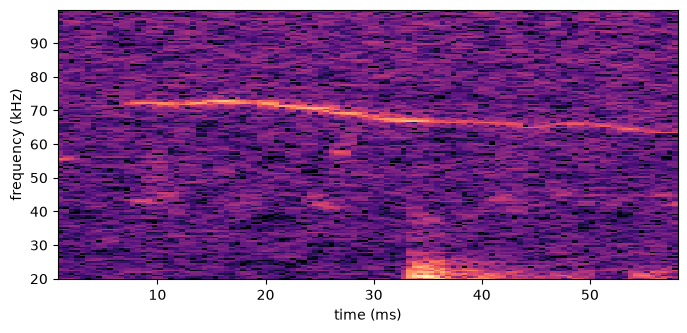

In [19]:
import glob, numpy as np, matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import spectrogram

p = glob.glob(f"{DATA_PATH}/**/DBA_3246_564*", recursive=True)[0]
sr, x = wavfile.read(p)
x = x.astype(float)
if x.ndim > 1:
    x = x[:, 0]

f, t, S = spectrogram(x, fs=sr, nperseg=512, noverlap=384)
keep = (f >= 20000) & (f <= 100000)
Sdb = 10 * np.log10(S[keep] + 1e-12)

plt.figure(figsize=(8, 3.5))
plt.pcolormesh(t * 1000, f[keep] / 1000, Sdb, shading="auto", cmap="magma", vmin=Sdb.max() - 50)
plt.xlabel("time (ms)")
plt.ylabel("frequency (kHz)")
plt.show()

In [20]:
print([n for n in dir(ja) if not n.startswith("_")])

['DATA_PATH', 'Path', 'argparse', 'binary_closing', 'binary_dilation', 'binary_opening', 'extract_raw_ridge', 'get_spectrogram', 'inspect_file', 'librosa', 'main', 'np', 'pd', 'plt', 'track_ridge_tfridge_like']


In [21]:
k = test_keys[0]
c0 = test_contours[k]
print({name: (list(v.keys()) if hasattr(v, "keys") else type(v)) for name, v in c0.items()})

{'has_multiple_ridges': <class 'numpy.bool'>, 'bottom_or_main': ['time_s', 'frequency_hz', 'amplitude', 'duration_s'], 'top': ['time_s', 'frequency_hz', 'amplitude', 'duration_s']}


In [22]:
import numpy as np

def contour_has_jump(r, thr=10, trim_s=0.005):
    t = np.asarray(r["time_s"], float)
    f = np.asarray(r["frequency_hz"], float) / 1000
    if len(t) < 10:
        return None
    dt = np.median(np.diff(t))
    for i in range(2, len(t) - 2):
        if t[i] - t[0] < trim_s or t[-1] - t[i] < trim_s:
            continue
        if t[i+1] - t[i-2] > 3.5 * dt:
            continue
        if abs(np.median(f[i:i+2]) - np.median(f[i-2:i])) >= thr:
            return True
    return False

In [23]:
def share(x):
    ok = [v for v in x if v is not None]
    return sum(ok), len(ok)

multi = [k for k in test_keys if test_contours[k]["has_multiple_ridges"]]
print(len(multi), "calls with more than one ridge")
print("bottom ridge, all calls", share([contour_has_jump(test_contours[k]["bottom_or_main"]) for k in test_keys]))
print("bottom ridge, multi ridge calls", share([contour_has_jump(test_contours[k]["bottom_or_main"]) for k in multi]))
print("top ridge, multi ridge calls", share([contour_has_jump(test_contours[k]["top"]) for k in multi]))

713 calls with more than one ridge
bottom ridge, all calls (304, 2077)
bottom ridge, multi ridge calls (10, 591)
top ridge, multi ridge calls (579, 713)


In [24]:
import json
json.dump(multi, open("multi_keys.json", "w"))

In [25]:
import json
from pathlib import Path
multi = json.load(open("multi_keys.json"))
stem = {Path(w).stem: w for w in wavs}
r = [has_jump(str(stem[k])) for k in multi if k in stem]
ok = [x for x in r if x is not None]
print(sum(ok), "of", len(ok), "multi ridge calls have a jump with the strongest tracker")

NameError: name 'wavs' is not defined